<a href="https://colab.research.google.com/github/riteshmishrarscse26-sketch/academic-cv/blob/main/model_inversion_colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Model Inversion Attack — MNIST version (Colab)

This is an optional upgrade of the experiment to use the *real* MNIST dataset (28x28 digit images) instead of the smaller scikit-learn `digits` dataset. Just run all cells top to bottom in Google Colab — it needs internet access to download MNIST, which Colab has by default.


In [ ]:
!pip install torch torchvision matplotlib -q

import torch
import torch.nn as nn
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = 'cuda' if torch.cuda.is_available() else 'cpu'

In [ ]:
# 1. Load real MNIST
transform = transforms.Compose([transforms.ToTensor()])
train_set = torchvision.datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST(root='./data', train=False, download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=128, shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=256, shuffle=False)

100%|██████████| 9.91M/9.91M [00:00<00:00, 57.0MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 39.0MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 77.6MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.56MB/s]


In [ ]:
# 2. Train a simple softmax (linear) classifier - mirrors the logistic regression
# used in the digits-dataset version for a fair comparison. Swap in a small CNN
# if you want to compare attack difficulty across model complexity.
model = nn.Linear(28*28, 10).to(device)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(5):
    for x, y in train_loader:
        x = x.view(x.size(0), -1).to(device)
        y = y.to(device)
        optimizer.zero_grad()
        out = model(x)
        loss = loss_fn(out, y)
        loss.backward()
        optimizer.step()
    print(f'epoch {epoch} loss {loss.item():.4f}')

# quick test accuracy
correct, total = 0, 0
with torch.no_grad():
    for x, y in test_loader:
        x = x.view(x.size(0), -1).to(device)
        y = y.to(device)
        pred = model(x).argmax(1)
        correct += (pred == y).sum().item()
        total += y.size(0)
print(f'Test accuracy: {correct/total:.4f}')

epoch 0 loss 0.5062
epoch 1 loss 0.3385
epoch 2 loss 0.2565
epoch 3 loss 0.3108
epoch 4 loss 0.3238
Test accuracy: 0.9179


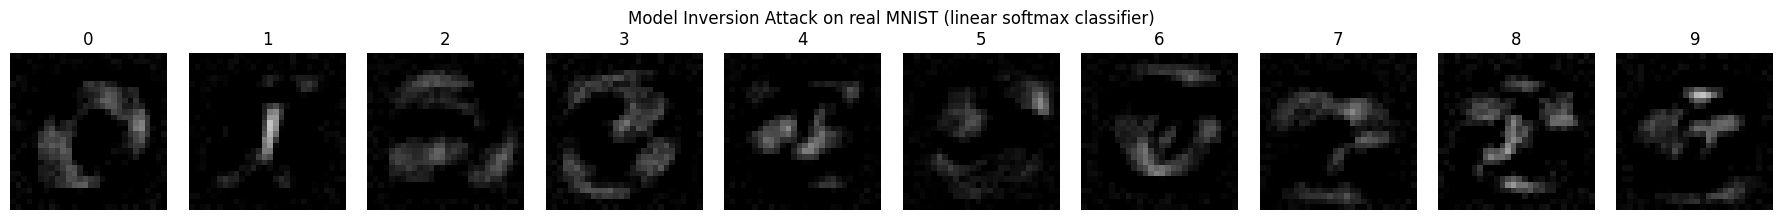

In [ ]:
# 3. Model inversion attack: gradient ASCENT on the input to maximize
# confidence for a target class, using only the trained model's gradients.
def invert(target_class, iters=2000, lr=0.5, l2=0.01):
    x = torch.full((1, 28*28), 0.5, requires_grad=True, device=device)
    target = torch.tensor([target_class], device=device)
    for i in range(iters):
        out = model(x)
        logp = torch.log_softmax(out, dim=1)
        loss = -logp[0, target_class] + l2 * (x ** 2).sum()
        model.zero_grad()
        if x.grad is not None:
            x.grad.zero_()
        loss.backward()
        with torch.no_grad():
            x -= lr * x.grad
            x.clamp_(0, 1)
    return x.detach().cpu().view(28, 28)

fig, axes = plt.subplots(1, 10, figsize=(18, 2.2))
for c in range(10):
    recon = invert(c)
    axes[c].imshow(recon, cmap='gray', vmin=0, vmax=1)
    axes[c].axis('off')
    axes[c].set_title(str(c))
plt.suptitle('Model Inversion Attack on real MNIST (linear softmax classifier)')
plt.tight_layout()
plt.savefig('mnist_inversion_results.png', dpi=150, bbox_inches='tight')
plt.show()

If you'd rather submit the MNIST version, swap the figure `mnist_inversion_results.png` into the blog post in place of `inversion_results.png`, and update the accuracy numbers and dataset description accordingly.